# Dar_021 — Multiobjective environmental trade-offs and preference sensitivity

**Objective:** environmental evidence for choosing a lunar base location together with terrain. This follows the original notebooks 31–32 diagnostic/comparison/interpretation flow, without changing their code, CNN artifacts or protected reserves.

## Questions and prior evidence

- Q17: Which units are nondominated in solar visibility, Earth visibility and slope?
- Q18: What trade-offs appear when light, Earth visibility or flatter terrain is preferred?
- Q19: How do ranks respond to a declared grid of diagnostic weights?
- Q20: Does physical-domain versus within-pool percentile normalization change the ranking?
- Q21: Which units repeatedly appear in diagnostic top-five sets, and how unstable are their ranks?
- Q22: How do regional representation and assessment-unit grain affect interpretation?
- Q23: What changes when one or more criteria have zero diagnostic weight?
- Q24: Are the three preference proxies correlated within each fixed comparison pool?

Read the accepted Dar_017/018 results before interpreting these extensions. The questions are related diagnostics, not independent experiments.

## Input contract and declared considerations

Two pools remain separate: original 1.2 km center-context blocks (including empty blocks) and purposive connected-component examples. Solar/Earth metrics are medians; slope is the 90th percentile, not a maximum. Three directional preferences are diagnostic assumptions: higher solar/Earth and lower slope. Compare 15 declared weight triples on the 0.25 simplex and two transformations. Physical-domain slope benefit is 1-slope/90; percentile benefits depend on the fixed pool. No best policy is selected, no correlations become weights, and all three fields are required even when a weight is zero.

In [1]:
from pathlib import Path
import sys,json
from itertools import product
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT/'darrel stuff/EDA'),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input
from environmental_selection_eda import *
import environmental_selection_eda as methods
DATA=ROOT/'darrel stuff/data'
REGION_LIMIT=None  # Set 1 for the initial representative sample, None for all seven.
JOINT_RUN_ID='20261106T134155791814Z_c6f9ab'
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment',JOINT_RUN_ID)
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=125,bbox_inches='tight');display(fig);plt.close(fig)
def register_methods(run):
    run.input(Path(methods.__file__))
    for name in ['moon_p1_analysis.py','site_comparison.py','decision_eda.py']:
        run.input(ROOT/'darrel stuff/EDA'/name)
    for name in ['31_vertical_scale_sensitivity.ipynb','32_candidate_coverage_and_ranking.ipynb']:
        run.input(ROOT/'notebooks/modeling/terrain_similarity'/name)
def publish(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8')
    display(record)
def selected_regions(values):
    regions=sorted(values)
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region sample')
        regions=regions[:REGION_LIMIT]
    return regions

Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab


In [2]:
CANDIDATE_RUN_ID=None  # Set an accepted run ID for exact reproduction.

## Build a new local run and compare the data

Inputs and helper source hashes are recorded. Results remain under `darrel stuff/data/processed/analysis/`; source downloads and earlier notebooks are not overwritten.

Accepted local analysis/dar_020_candidate_environment run: 20261106T175311055762Z_b68ce6


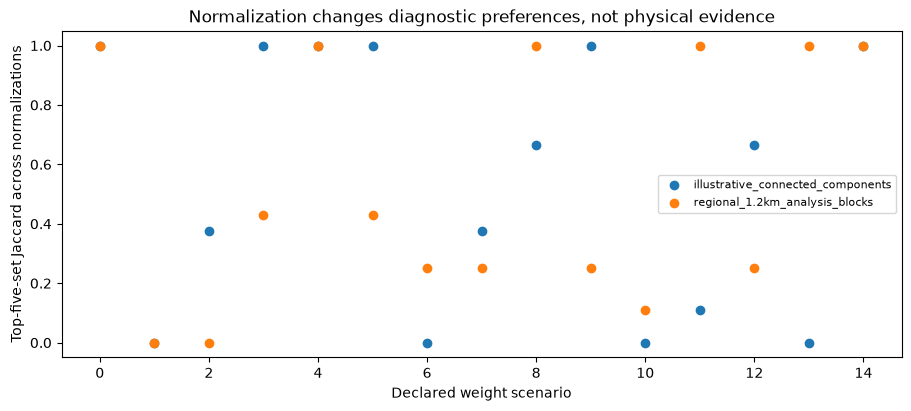

,min,median,max
pool,,,
illustrative_connected_components,0.0,0.666667,1.0
regional_1.2km_analysis_blocks,0.0,0.428571,1.0


pool                               pareto_status
illustrative_connected_components  dominated           8
                                   nondominated       13
regional_1.2km_analysis_blocks     Unknown            17
                                   dominated        2389
                                   nondominated       24
Name: units, dtype: int64

**Observed influence:** changes in diagnostic ranks are produced by declared preference/normalization choices on fixed physical data. Report the Pareto trade-offs and sensitivity instead of presenting one arbitrary weighted order as a physical fact.

{'questions': ['Q17', 'Q18', 'Q19', 'Q20', 'Q21', 'Q22', 'Q23', 'Q24'],
 'regions': 7,
 'comparison_units': 2451,
 'units_per_pool': {'illustrative_connected_components': 21,
  'regional_1.2km_analysis_blocks': 2430},
 'unscored_units': 17,
 'pareto_status_counts': [{'pool': 'illustrative_connected_components',
   'pareto_status': 'dominated',
   'units': 8},
  {'pool': 'illustrative_connected_components',
   'pareto_status': 'nondominated',
   'units': 13},
  {'pool': 'regional_1.2km_analysis_blocks',
   'pareto_status': 'Unknown',
   'units': 17},
  {'pool': 'regional_1.2km_analysis_blocks',
   'pareto_status': 'dominated',
   'units': 2389},
  {'pool': 'regional_1.2km_analysis_blocks',
   'pareto_status': 'nondominated',
   'units': 24}],
 'scaling_jaccard_by_pool': [{'pool': 'illustrative_connected_components',
   'min': 0.0,
   'median': 0.6666666666666666,
   'max': 1.0},
  {'pool': 'regional_1.2km_analysis_blocks',
   'min': 0.0,
   'median': 0.42857142857142855,
   'max': 1.0}]

In [3]:
candidate=latest_completed_run(ROOT,'analysis/dar_020_candidate_environment',CANDIDATE_RUN_ID)
with Run(ROOT,'analysis/dar_021_preference_influence',{'region_limit':REGION_LIMIT,'candidate_run':str(candidate.relative_to(ROOT)),
    'joint_run':str(joint.relative_to(ROOT)),'weights':'all 15 simplex triples in increments of 0.25',
    'normalizations':['physical_domain','within_pool_percentile'],'adopted_weights':None,'operational_ranking':False},
    'Moon/Site_Assessment/Dar_021_environment_preference_sensitivity.ipynb') as run:
    register_methods(run)
    blocks=pd.read_csv(accepted_input(run,joint,'candidate_block_context.csv'))
    centers=pd.read_csv(accepted_input(run,joint,'native_center_context.csv.gz'))
    regions=selected_regions(blocks.region.unique());blocks=blocks.loc[blocks.region.isin(regions)];centers=centers.loc[centers.region.isin(regions)]
    block_pool=comparison_pool(blocks,centers)
    component_pool=pd.read_csv(accepted_input(run,candidate,'connected_component_comparison_pool.csv'))
    component_pool=component_pool.loc[component_pool.region.isin(regions)]
    pool=pd.concat([block_pool,component_pool],ignore_index=True)
    if pool.unit_id.duplicated().any():raise ValueError('Comparison unit identity collision')
    pool.to_csv(run.path('comparison_units.csv'),index=False)
    rankings=[];pareto=[];correlations=[]
    for family,part in pool.groupby('pool'):
        rankings.append(preference_scenarios(part));pareto.append(pareto_dominance(part))
        for a,b in [('solar_fraction','earth_fraction'),('solar_fraction','slope_deg'),('earth_fraction','slope_deg')]:
            chosen=part[[a,b]].replace([np.inf,-np.inf],np.nan).dropna()
            correlations.append({'pool':family,'field_a':a,'field_b':b,'units':len(chosen),
                'spearman_rho':chosen[a].corr(chosen[b],method='spearman') if chosen[a].nunique()>1 and chosen[b].nunique()>1 else np.nan})
    ranking=pd.concat(rankings,ignore_index=True);dominance=pd.concat(pareto,ignore_index=True)
    ranking['in_diagnostic_top5']=ranking.diagnostic_rank.le(5)
    stability=ranking.groupby(['pool','unit_id','region']).agg(scenarios=('scenario_id','size'),
        scored_scenarios=('diagnostic_rank','count'),minimum_rank=('diagnostic_rank','min'),
        maximum_rank=('diagnostic_rank','max'),top5_scenarios=('in_diagnostic_top5','sum')).reset_index()
    stability['rank_span']=stability.maximum_rank-stability.minimum_rank
    scaling=[]
    for family,part in ranking.groupby('pool'):
        for weight,group in part.groupby(['solar_weight','earth_weight','slope_weight']):
            a=group.loc[group.normalization.eq('physical_domain')].set_index('unit_id')
            b=group.loc[group.normalization.eq('within_pool_percentile')].set_index('unit_id')
            left=set(a.index[a.diagnostic_rank.le(5)]);right=set(b.index[b.diagnostic_rank.le(5)])
            joined=a[['diagnostic_rank']].join(b[['diagnostic_rank']],lsuffix='_physical',rsuffix='_percentile')
            scaling.append({'pool':family,'solar_weight':weight[0],'earth_weight':weight[1],'slope_weight':weight[2],
                'physical_top5_with_ties':len(left),'percentile_top5_with_ties':len(right),'intersection':len(left&right),
                'top5_jaccard':len(left&right)/len(left|right) if left|right else np.nan,
                'rank_spearman':joined.corr(method='spearman').iloc[0,1]})
    scaling=pd.DataFrame(scaling)
    ranking.to_csv(run.path('diagnostic_preference_scenarios.csv.gz'),index=False,compression={'method':'gzip','mtime':0})
    dominance.to_csv(run.path('pareto_dominance.csv'),index=False)
    stability.to_csv(run.path('diagnostic_rank_stability.csv'),index=False)
    scaling.to_csv(run.path('normalization_comparison.csv'),index=False)
    pd.DataFrame(correlations).to_csv(run.path('preference_metric_correlations.csv'),index=False)
    ranking.loc[ranking.in_diagnostic_top5].groupby(['pool','scenario_id','region']).size().rename('top5_units_with_ties').to_csv(run.path('regional_top5_representation.csv'))
    fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
    for family,p in scaling.groupby('pool'):ax.scatter(range(len(p)),p.top5_jaccard,label=family)
    ax.set(xlabel='Declared weight scenario',ylabel='Top-five-set Jaccard across normalizations',title='Normalization changes diagnostic preferences, not physical evidence');ax.legend(fontsize=8)
    savefig(run,fig,'normalization_rank_sensitivity')
    display(scaling.groupby('pool').top5_jaccard.agg(['min','median','max']))
    display(dominance.groupby(['pool','pareto_status']).size().rename('units'))
    display(Markdown('**Observed influence:** changes in diagnostic ranks are produced by declared preference/normalization choices on fixed physical data. Report the Pareto trade-offs and sensitivity instead of presenting one arbitrary weighted order as a physical fact.'))
    publish(run,{'questions':['Q%02d'%i for i in range(17,25)],'regions':len(regions),'comparison_units':len(pool),
        'units_per_pool':pool.groupby('pool').size().to_dict(),'unscored_units':int(stability.scored_scenarios.eq(0).sum()),
        'pareto_status_counts':dominance.groupby(['pool','pareto_status']).size().reset_index(name='units').to_dict('records'),
        'scaling_jaccard_by_pool':scaling.groupby('pool').top5_jaccard.agg(['min','median','max']).reset_index().to_dict('records'),
        'limits':['Weights and transformations are predeclared diagnostics, not adopted preferences',
        'Top-five sets include rank ties; frequency is not a probability of being best','Pools and spatial grains stay separate',
        'No operational ranking while mandatory requirements remain unresolved']})
OUT=run.directory

## Findings and observed influence

Read the executed `findings.json`, tables and plots above; counts and missing groups are part of the result. An observed rank/availability change is sensitivity under the declared controls, not evidence that the changed setting is correct.

## Effect on hard rules and soft preferences

Pareto comparisons expose trade-offs before weights; rank sensitivity exposes policy dependence. Ties remain tied and top-five sets may exceed five. These diagnostic scores cannot be used as operational rankings while mandatory requirements remain unresolved. Do not double-count slope already used in terrain assessment.

## Implementation handoff and next decision

Reuse the functions in `../../environmental_selection_eda.py` and retain source/assessment-unit contracts. Compare available evidence before adopting any rule. See [EDA work plan and questions](../../EDA_Notes.md#eda-question-register), [EDA results](../../EDA_Results.md) and [the proposal](../../../Brief_Overview.md#algorithm-proposal) for the full EDA → influence → proposed implementation chain. Exact CNN-patch matching remains optional; local, regional and reference evidence must not be conflated.

## Save reusable data and disposable reports

The completed run above already saved reusable tables, plots, `findings.json` and provenance together. Later notebooks read accepted table exports rather than notebook display outputs. Clear/regenerate disposable reports only if intended; no source data were deleted.